# Customer Segmentation with Clustering
**Goal:** segment a set of wholesale customers into groups using k-means, decide how many
groups with the **elbow method** and the **silhouette score**, and explain what each segment is.



## Your dataset

Use the **Wholesale Customers** dataset: annual spending (monetary units) by 440 clients of a
wholesale distributor across product categories.

- Download: [UCI Wholesale Customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers) (also searchable as "Wholesale customers" on Kaggle).
- Columns: `Channel`, `Region` (these are labels, not spending), then the six spend columns `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.
- Cluster on the **six spend columns**. `Channel` and `Region` are context only; do not cluster on them.

In [2]:
# Step 0: imports (given - just run this)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

ETSU_NAVY = "#00053E"
ETSU_GOLD = "#FFC72C"
print("Ready.")

Ready.


## Step 1: Load the data

Change the path to the real Wholesale file when you have it.

In [3]:
# GIVEN: load the data
df = pd.read_csv("./Wholesale customers data.csv")
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## Step 2: Explore

Look at the data before clustering: size, column types, and the ranges of the spend columns
(the ranges tell you whether scaling is needed).

In [8]:
# TODO: explore the data
# Hint: df.shape, df.info(), and df[spend_cols].describe()

print(df.shape)
print()
df.info()
print()
df[spend_cols].describe()



(440, 8)

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB



,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


## Step 3: Select features and scale

k-means uses distance, and these spend columns are on very different scales, so scale them.

- Build X from the six spend columns.
- Scale with StandardScaler.

In [9]:
# TODO: build X from the spend columns and scale it
X = df[spend_cols].values
Xs = StandardScaler().fit_transform(X)




## Step 4: Choose the number of clusters (elbow + silhouette)

Try a range of k (say 2 to 10). For each k, fit k-means and record two things:

- `kmeans.inertia_` for the **elbow** plot (tightness; look for where the curve bends),
- `silhouette_score(Xs, labels)` for the **silhouette** plot (separation; higher is better).

Plot both, then pick a k and justify it in a sentence.

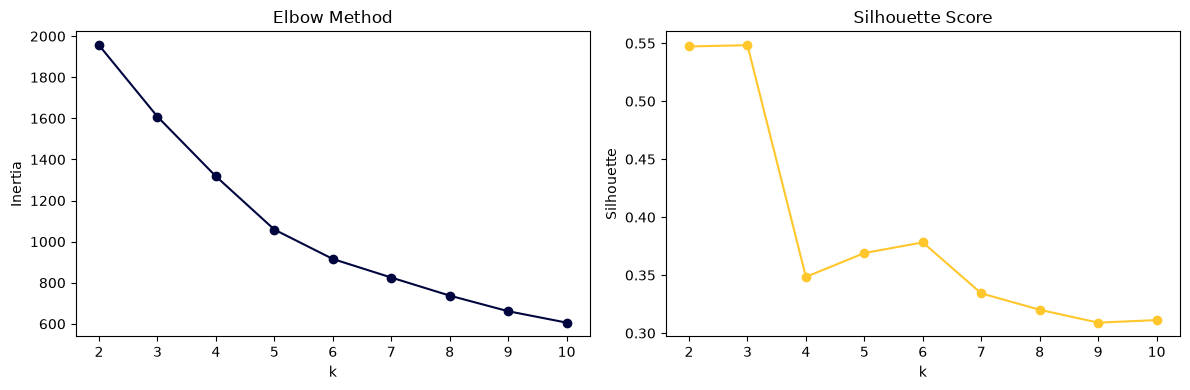

k=2: silhouette = 0.547215
k=3: silhouette = 0.548287
k=4: silhouette = 0.348471
k=5: silhouette = 0.369040
k=6: silhouette = 0.378229
k=7: silhouette = 0.334282
k=8: silhouette = 0.320116
k=9: silhouette = 0.309028
k=10: silhouette = 0.311214


In [16]:
# TODO: loop over k, collect inertia and silhouette, then plot both
# Hint:
ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xs, km.labels_))
# then make two plots: ks vs inertias, and ks vs sils



fig, axes = plt.subplots(1, 2, figsize = (12, 4))

axes[0].plot(ks, inertias, marker="o", color = ETSU_NAVY)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")

axes[1].plot(ks, sils, marker="o", color = ETSU_GOLD)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

for k,s in zip(ks, sils):
    print(f"k={k}: silhouette = {s:3f}")



**Your chosen k and why:**

I chose k=3 because it has the highest silhouette score (0.548) and then it is followed by a sharp drop at k=4 where the score goes to 0.348. The elbow plot doesn't really show any other bends that would indicate that there are more clusters.

## Step 5: Fit k-means with your chosen k

In [18]:
# TODO: fit KMeans at your chosen k and attach the labels to df
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(Xs)
df["cluster"] = kmeans.labels_



## Step 6: Visualize the clusters with PCA

You have six features, so you cannot plot them directly. Reduce the scaled data to 2D with PCA
and color the points by cluster.

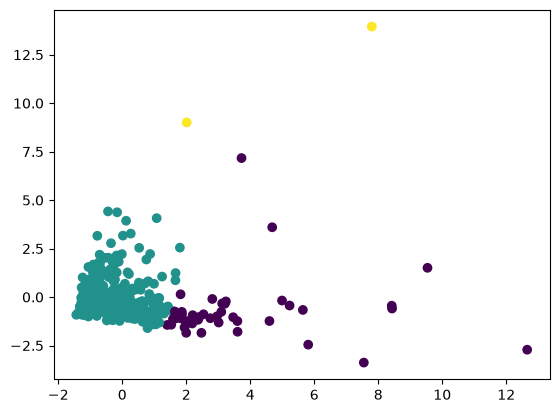

In [19]:
# TODO: project Xs to 2D with PCA and scatter it, colored by df["cluster"]
pcs = PCA(n_components=2).fit_transform(Xs)
plt.scatter(pcs[:,0], pcs[:,1], c=df["cluster"])




## Step 7: Profile and interpret the segments

Summarize each cluster by the average of each spend column (and how many customers are in it),
then describe each segment in plain words.

In [25]:
# TODO: build a profile table of per-cluster averages
print(df.groupby("cluster")[spend_cols].mean().round(0))
df["cluster"].value_counts() 




           Fresh     Milk  Grocery   Frozen  Detergents_Paper  Delicassen
cluster                                                                  
0        10441.0  19386.0  28656.0   2190.0           13328.0      2374.0
1        12063.0   4115.0   5535.0   2941.0            1696.0      1299.0
2        34782.0  30367.0  16898.0  48702.0             756.0     26776.0


cluster
1    393
0     45
2      2
Name: count, dtype: int64

## Step 8: Findings

1. **How many clusters did you choose, and why?** (what the elbow and silhouette showed)

2. **Describe each segment** in plain language. What kind of customer is it (for example, a grocery-heavy retailer vs a fresh-and-frozen restaurant supplier)?
3. **One action per segment:** what should the distributor do differently for each group?
4. **One limitation:** what would you want to check or try next (different k, more features, outliers)?

Answer for 1. 
The k value that I chose is k=3 because that is where the silhouette is the highest, and when you look at the elbow plot, there aren't any clear bends indicating that there are no more clusters.

Answer for 2. 
When looking at the grocery-heavy retailer segment, there are 45 customers who spend far above average on things like Grocery, Milk, and Detergent Paper, while spending a little below average on Fresh. That means these are most likely supermarkets or retail stores based on the results gained. The second segment is the typical small customers, 393 of them, mainly spends average on Fresh, while the other categories are below average. If this is the case, then these are mainly restaurants or cafes. Lastly, there are extreme food-service accounts, 2 of them, who spend a tremendous amount on Frozen and Deli, while also spending higher than average on Milk and Fresh. However, they spend very low on Detergent Papers, so this means they are most likely catering companies or food service.

Answer for 3. 
For the first cluster, the distributor should offer discounts and schedule restocking on things like Milk, Grocery, and Paper goods in bulk. For the second cluster, the distributor should provide consistent reliable Fresh deliveries and add supplementary goods from the other categories to help boost order size. Lastly, the distributor should hire people like managers to overlook the Frozen and Deli products and be able to set up contracts with clients for those goods.

Answer for 4.
A limitation here is that one cluster contains a large amount of the data as the second cluster includes 393/440 customers. This leads to skewed spending and there are some outliers that help inflate the score. I would try to remove the outliers, and rerun the elbow plot and the silhouette score and see if the second cluster splits into more groups.

## Submission checklist

- This notebook, renamed `Lastnames_Clustering.ipynb`, all cells run with output showing